%pip install numpy matplotlib

In [57]:
import numpy as np 
import matplotlib.pyplot as plt 

In [77]:
np.random.seed(2004)

In [78]:
n = 1000
data = np.random.randn(n, 2)
data[:, 0] *= 3 
rot = np.array([
    [0.866, -0.5],
    [0.5, 0.866]
]) 
data_rot = data @ rot.T
data_rot[:, 0] += 1
data_rot[:, 1] += 3
data_rot.shape

(1000, 2)

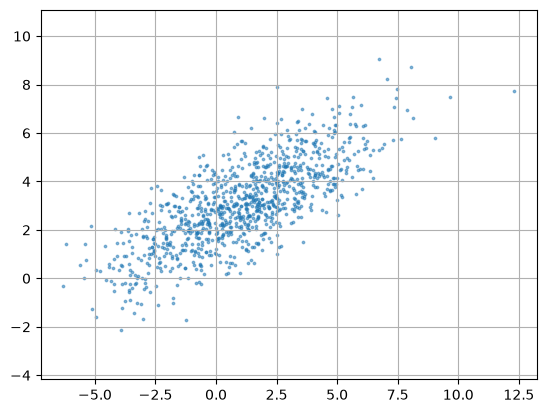

In [79]:
plt.scatter(data_rot[:, 0], data_rot[:, 1], s=3, alpha=0.5)
plt.grid()
plt.axis('equal')
plt.show()

In [86]:
data_mean = np.mean(data_rot, axis=0)
data_centred = np.zeros(shape=(n, 2))
data_centred = data_rot - data_mean
data_centred.shape

(1000, 2)

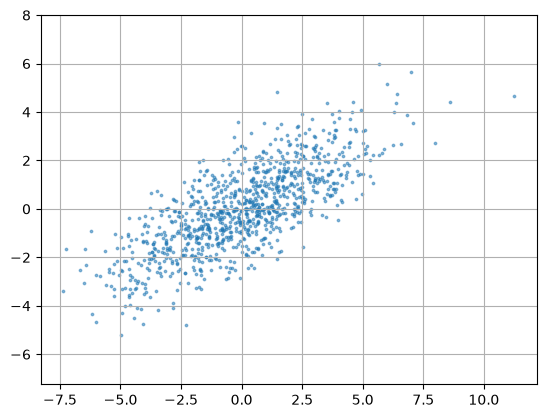

In [87]:
plt.scatter(data_centred[:, 0], data_centred[:, 1], s=3, alpha=0.5)
plt.grid()
plt.axis('equal')
plt.show()

In [89]:
cov_mat = data_centred.T @ data_centred / (n - 1)

In [90]:
eigen_mat = np.linalg.eigh(cov_mat)
eigen_mat

EighResult(eigenvalues=array([1.02429297, 9.09691922]), eigenvectors=array([[ 0.50103286, -0.86542826],
       [-0.86542826, -0.50103286]]))

In [100]:
ids = np.argsort(eigen_mat.eigenvalues)[::-1]
values = eigen_mat.eigenvalues[ids]
vectors = eigen_mat.eigenvectors[:, ids]
values, vectors 

(array([9.09691922, 1.02429297]),
 array([[-0.86542826,  0.50103286],
        [-0.50103286, -0.86542826]]))

In [102]:
eigen_mat.eigenvalues / eigen_mat.eigenvalues.sum()

array([0.1012026, 0.8987974])

In [104]:
top = vectors[:, :k]
top

array([[-0.86542826],
       [-0.50103286]])

In [105]:
Z = np.dot(data_centred, top)
Z.shape

(1000, 1)

In [106]:
Z.var(ddof=1)

np.float64(9.09691922239323)

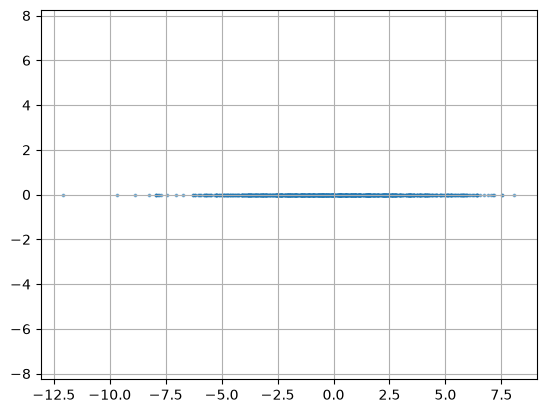

In [110]:
plt.scatter(Z, np.zeros(n), s=3, alpha=0.5)
plt.grid()
plt.axis('equal')
plt.show()

(1000, 2)


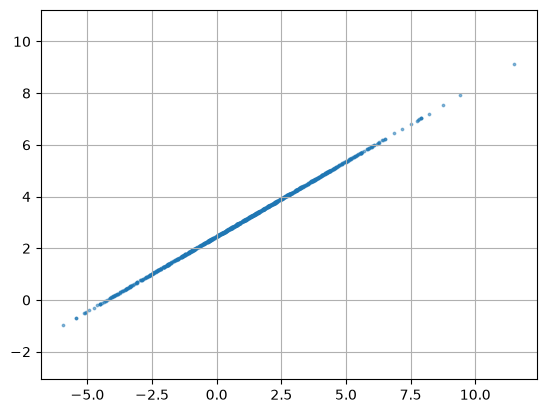

In [116]:
res = (Z @ top.T) + data_mean
print(res.shape)
plt.scatter(res[:, 0], res[:, 1], s=3, alpha=0.5)
plt.grid()
plt.axis('equal')
plt.show()